# Stage 3 Verification: Full-Chassis Physics, Aero Drag & Progressive Bumpstop

This notebook unifies zero-shot calibration coefficient verification with full-chassis suspension and longitudinal aerodynamic drag verification (zero SINDy / pure first-principles physics):

1. **Main-Straight Aerodynamic Drag (`0–700 m`)**: Verifies whether the calibrated rear wing (`dcd_wing`) and front/rear brake duct drag (`dcd_ducts`) reproduce the observed main-straight speed curve.
2. **Calibration & Progressive Bumpstop Verification**: Checks zero-shot bumpstop engagement threshold accuracy and demonstrates how ACC's progressive bumpstop law ($F_{\text{bs}} = k_{\text{prog}} (z - z_{\text{thr}})^{2.73}$) eliminates post-engagement front-axle suspension travel error.
3. **Scenario Suspension Verification (Observed vs. Stage 3 Physics)**:
   - Segments 1–4 (`Main Straight`, `T1 Braking`, `T3 Long Corner`, `T4–T5 Trail Braking`): side-by-side Front (`LF/RF`, left) vs. Rear (`LR/RR`, right) suspension travel.
   - Segment 5 (`T10–T16 Continuous Complex to Finish`, `3150–4586 m`): **two separate full-width figures** (Front Axle and Rear Axle).

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

def show_and_save(fig, path):
    fig.savefig(path, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path)))

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import (
    load_config,
    load_motec_csv,
    curate_telemetry,
    verify_calibrated_coefficients,
    verify_straight_aero_drag,
    verify_stage3_scenarios,
)
from src.modeling.stage3_verification import SCENARIO_WINDOWS_M

plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.3})

cfg = load_config(ROOT / 'configs/experiments/stage3_verification/barcelona__audi_r8_gt3_evo2__r8_A.yaml')
OUT_DIR = ROOT / 'outputs' / cfg.experiment_name
OUT_DIR.mkdir(parents=True, exist_ok=True)

COLS = [
    'Time', 'Distance', 'ROTY', 'STEERANGLE', 'SPEED', 'G_LAT', 'G_LON', 'THROTTLE', 'BRAKE',
    'SUS_TRAVEL_LF', 'SUS_TRAVEL_RF', 'SUS_TRAVEL_LR', 'SUS_TRAVEL_RR',
    'BUMPSTOPUP_RIDE_LF', 'BUMPSTOPUP_RIDE_RF', 'BUMPSTOPUP_RIDE_LR', 'BUMPSTOPUP_RIDE_RR',
    'BUMPSTOP_FORCE_LF', 'BUMPSTOP_FORCE_RF', 'BUMPSTOP_FORCE_LR', 'BUMPSTOP_FORCE_RR',
    'TYRE_PRESS_LF', 'TYRE_PRESS_RF', 'TYRE_PRESS_LR', 'TYRE_PRESS_RR',
]

raw_tr, m_tr = load_motec_csv(ROOT / cfg.data.clean_csv, channels=COLS)
df_tr = curate_telemetry(raw_tr, m_tr, cfg.curation, trim_mode='none')

raw_val, m_val = load_motec_csv(ROOT / cfg.data.race_csv, channels=COLS)
df_val = curate_telemetry(raw_val, m_val, cfg.curation, trim_mode='none')

print(f'Training lap: {len(df_tr)} samples | Distance: {df_tr["LAP_DIST_M"].min():.1f} - {df_tr["LAP_DIST_M"].max():.1f} m')
print(f'Verification lap: {len(df_val)} samples | Distance: {df_val["LAP_DIST_M"].min():.1f} - {df_val["LAP_DIST_M"].max():.1f} m')

Training lap: 2130 samples | Distance: 0.0 - 4585.0 m
Verification lap: 2129 samples | Distance: 0.0 - 4586.0 m


## 1. Straight-Line Aerodynamic Drag Verification (Rear Wing + Brake Ducts)

Using the calibrated `wing = 0` net longitudinal acceleration curve (`test1.csv`) plus the setup's rear wing (`dcd_wing`) and brake duct (`dcd_ducts`) drag coefficients from `vehicle.yaml`, we integrate $v(s)$ along the main straight (`0–700 m`) and compare against the observed speed trace.

,Dataset,rmse_kmh,end_v_obs_kmh,end_v_pred_kmh,end_v_no_ducts_kmh,dcd_wing,dcd_ducts
0,Training,0.896,269.97,271.73,279.28,0.0365,0.0124
1,Verification,1.030,269.96,271.98,279.57,0.0365,0.0124


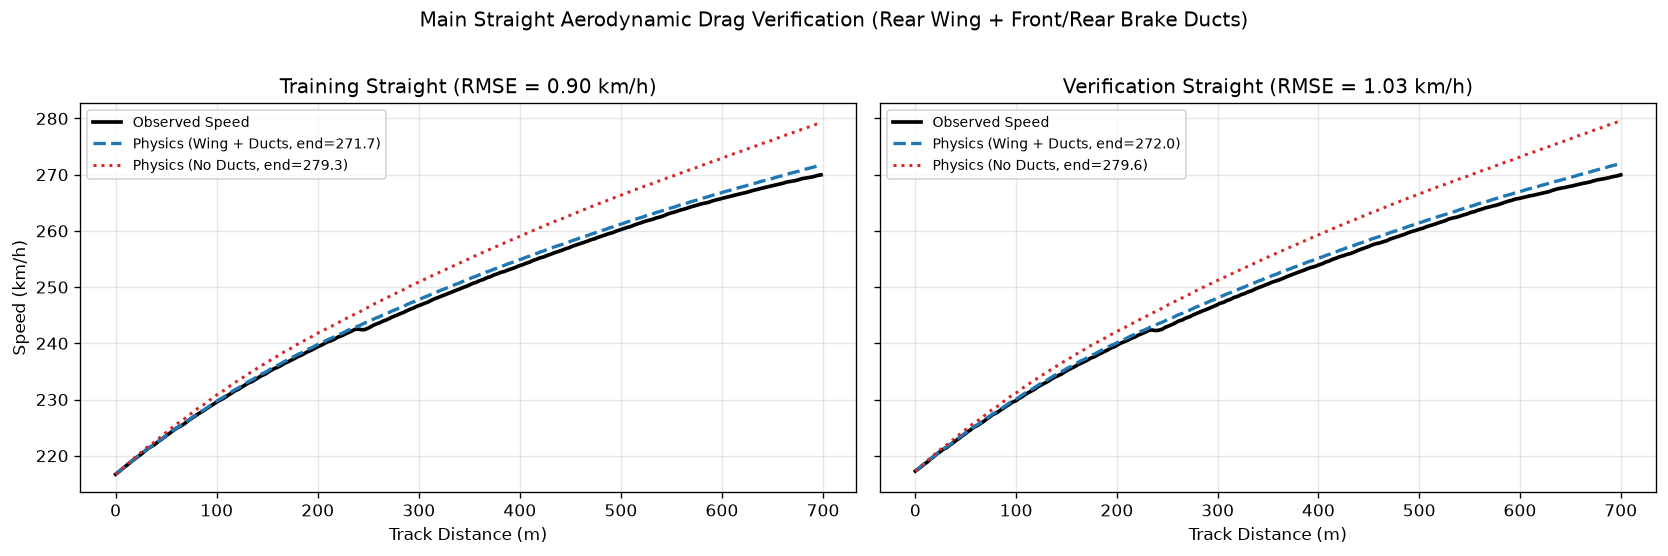

In [2]:
calib_dir = ROOT / 'data/calibration/audi_r8_gt3_evo2'
aero_tr = verify_straight_aero_drag(df_tr, cfg.car, cfg.setup, calib_dir, fuel_liters=2.0)
aero_val = verify_straight_aero_drag(df_val, cfg.car, cfg.setup, calib_dir, fuel_liters=2.0)

aero_df = pd.DataFrame([
    {'Dataset': 'Training', **aero_tr.to_dict()},
    {'Dataset': 'Verification', **aero_val.to_dict()},
])
display(aero_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, res, title in [
    (ax1, aero_tr, f'Training Straight (RMSE = {aero_tr.rmse_kmh:.2f} km/h)'),
    (ax2, aero_val, f'Verification Straight (RMSE = {aero_val.rmse_kmh:.2f} km/h)'),
]:
    ax.plot(res.dist_m, res.v_obs_kmh, 'k-', lw=2.2, label='Observed Speed')
    ax.plot(res.dist_m, res.v_pred_kmh, 'tab:blue', ls='--', lw=2.0, label=f'Physics (Wing + Ducts, end={res.end_v_pred_kmh:.1f})')
    ax.plot(res.dist_m, res.v_no_ducts_kmh, 'tab:red', ls=':', lw=1.8, label=f'Physics (No Ducts, end={res.end_v_no_ducts_kmh:.1f})')
    ax.set_title(title)
    ax.set_xlabel('Track Distance (m)')
    ax.legend(fontsize=8.5)
ax1.set_ylabel('Speed (km/h)')
fig.suptitle('Main Straight Aerodynamic Drag Verification (Rear Wing + Front/Rear Brake Ducts)', y=1.02, fontsize=12)
fig.tight_layout()
show_and_save(fig, OUT_DIR / '0_straight_aero_drag.png')

## 2. Calibration Coefficients & Progressive Bumpstop Verification

ACC MoTeC exports compression bumpstop force as **negative** values (`BUMPSTOP_FORCE_* < 0` when `BUMPSTOPUP_RIDE_* == 1`), following a progressive power law rather than a linear wall. Below we verify the zero-shot calibration thresholds and compare predicted vs. observed compression bumpstop force on `T1` heavy braking (`700–960 m`).

,Dataset,Corner,Pred Threshold (mm),Obs Min Engaged (mm),Accuracy (%),Engaged Frames
0,Training,LF,22.0,22.0,97.23,999
1,Training,RF,22.0,22.0,98.73,677
2,Training,LR,38.0,38.0,98.54,107
3,Training,RR,38.0,38.0,99.53,49
4,Verification,LF,22.0,22.0,96.71,982
5,Verification,RF,22.0,22.0,98.54,669
6,Verification,LR,38.0,38.0,99.15,99
7,Verification,RR,38.0,38.0,99.44,58


Training In-Bumpstop Travel RMSE -> LF: 1.65 mm | RF: 2.05 mm
Verification In-Bumpstop Travel RMSE -> LF: 1.89 mm | RF: 2.13 mm


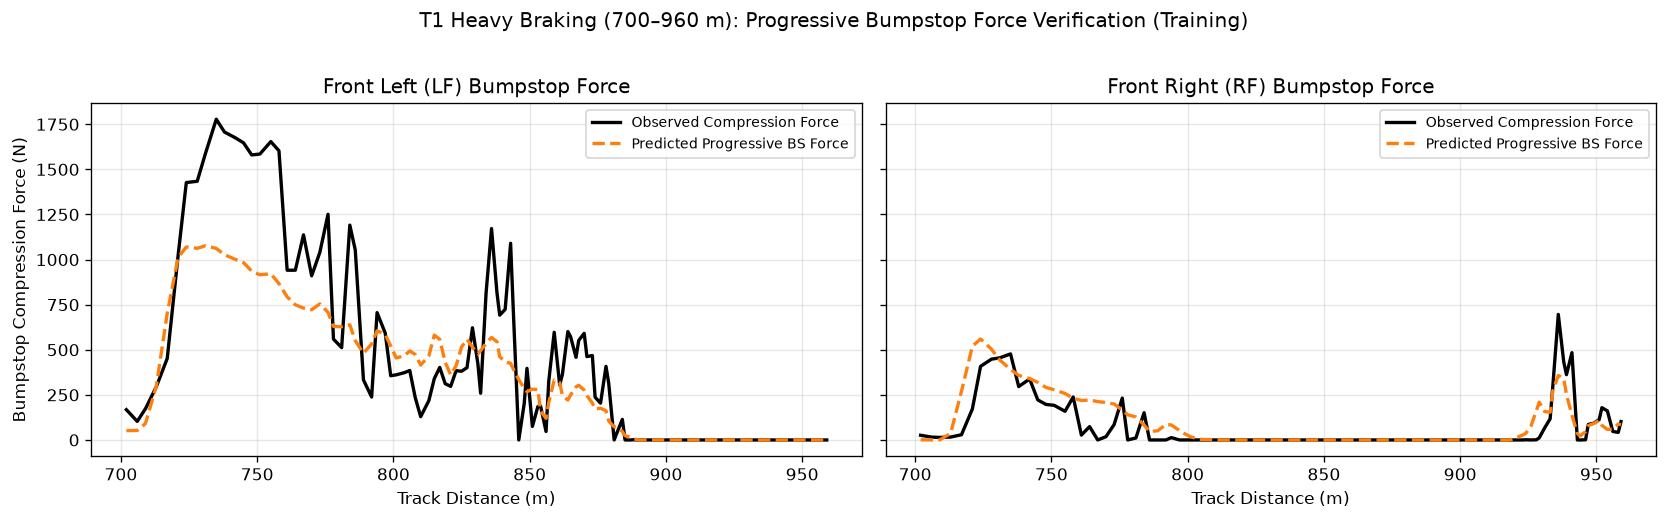

In [3]:
cal_tr = verify_calibrated_coefficients(raw_tr, df_tr, cfg.car, cfg.setup, fuel_liters=2.0)
cal_val = verify_calibrated_coefficients(raw_val, df_val, cfg.car, cfg.setup, fuel_liters=2.0)

bs_rows = []
for label, cal in [('Training', cal_tr), ('Verification', cal_val)]:
    for c, m in cal.bumpstop.items():
        bs_rows.append({
            'Dataset': label,
            'Corner': c,
            'Pred Threshold (mm)': round(m.predicted_threshold_mm, 2),
            'Obs Min Engaged (mm)': round(m.observed_min_engaged_mm, 2) if m.observed_min_engaged_mm is not None else None,
            'Accuracy (%)': round(m.classification_accuracy_pct, 2),
            'Engaged Frames': m.engaged_frames,
        })
display(pd.DataFrame(bs_rows))

state_tr, scen_tr = verify_stage3_scenarios(df_tr, cfg.car, cfg.setup, fuel_liters=2.0)
state_val, scen_val = verify_stage3_scenarios(df_val, cfg.car, cfg.setup, fuel_liters=2.0)

for label, raw, state in [('Training', raw_tr, state_tr), ('Verification', raw_val, state_val)]:
    bs_lf = (raw['BUMPSTOPUP_RIDE_LF'] == 1).to_numpy()
    bs_rf = (raw['BUMPSTOPUP_RIDE_RF'] == 1).to_numpy()
    rmse_lf = float(np.sqrt(np.mean((state.z_obs_mm['LF'][bs_lf] - state.z_pred_mm['LF'][bs_lf]) ** 2)))
    rmse_rf = float(np.sqrt(np.mean((state.z_obs_mm['RF'][bs_rf] - state.z_pred_mm['RF'][bs_rf]) ** 2)))
    print(f'{label} In-Bumpstop Travel RMSE -> LF: {rmse_lf:.2f} mm | RF: {rmse_rf:.2f} mm')

dist = df_tr['LAP_DIST_M'].to_numpy()
mask_t1 = (dist >= 700.0) & (dist <= 960.0)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, corner, title in [(ax1, 'LF', 'Front Left (LF) Bumpstop Force'), (ax2, 'RF', 'Front Right (RF) Bumpstop Force')]:
    ax.plot(dist[mask_t1], state_tr.bs_force_obs_n[corner][mask_t1], 'k-', lw=2.0, label='Observed Compression Force')
    ax.plot(dist[mask_t1], state_tr.bs_force_pred_n[corner][mask_t1], 'tab:orange', ls='--', lw=2.0, label='Predicted Progressive BS Force')
    ax.set_title(title)
    ax.set_xlabel('Track Distance (m)')
    ax.legend(fontsize=8.5)
ax1.set_ylabel('Bumpstop Compression Force (N)')
fig.suptitle('T1 Heavy Braking (700–960 m): Progressive Bumpstop Force Verification (Training)', y=1.02, fontsize=12)
fig.tight_layout()
show_and_save(fig, OUT_DIR / '0b_progressive_bumpstop_t1.png')

## 3. Continuous Track Scenario Suspension Verification

Summary table across all five Barcelona segments, followed by:
- **Segments 1–4**: Left subplot = Front Axle (`LF` & `RF`), Right subplot = Rear Axle (`LR` & `RR`).
- **Segment 5 (`T10–T16`, `3150–4586 m`)**: Two separate full-width figures (`5a_t10_t16_front.png` and `5b_t10_t16_rear.png`).

,Dataset,Scenario,Samples,Mean Corner RMSE (mm),LF (mm),RF (mm),LR (mm),RR (mm),Max BS Obs (N),Max BS Pred (N)
0,Training,1. Main Straight (Aero Drag & Pitch Attitude),207,1.748,1.630,1.789,1.794,1.781,692.0,190.4
1,Training,2. T1 Heavy Braking (Pitch & Progressive Bumps...,126,2.713,2.172,2.447,2.987,3.245,2255.0,1629.4
2,Training,3. T3 High-Speed Long Corner (Aero + Lateral),252,1.873,1.410,2.205,2.113,1.765,447.0,383.6
3,Training,4. T4–T5 Trail Braking & Turn-In (Combined),415,2.203,2.102,2.113,2.306,2.289,1448.0,1100.7
4,Training,5. T10–T16 Continuous Complex to Finish (Braki...,781,2.896,2.914,2.764,2.946,2.960,2668.0,1243.8
5,Verification,1. Main Straight (Aero Drag & Pitch Attitude),206,1.693,1.559,1.691,1.736,1.785,618.0,383.6
6,Verification,2. T1 Heavy Braking (Pitch & Progressive Bumps...,126,3.340,2.640,2.937,3.681,4.102,2097.0,1718.3
7,Verification,3. T3 High-Speed Long Corner (Aero + Lateral),258,3.272,3.072,3.194,3.559,3.262,2711.0,510.1
8,Verification,4. T4–T5 Trail Braking & Turn-In (Combined),410,2.241,2.153,2.188,2.219,2.405,1685.0,1097.1
9,Verification,5. T10–T16 Continuous Complex to Finish (Braki...,778,2.762,2.571,2.837,2.705,2.935,2437.0,1217.8


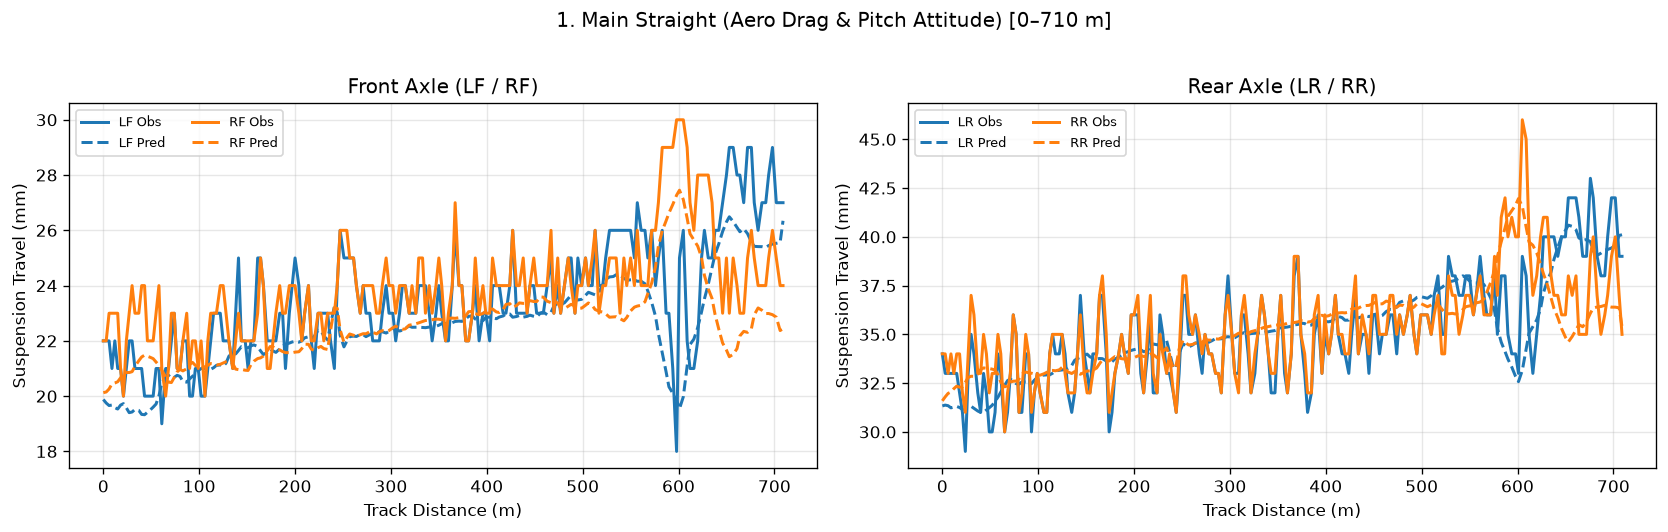

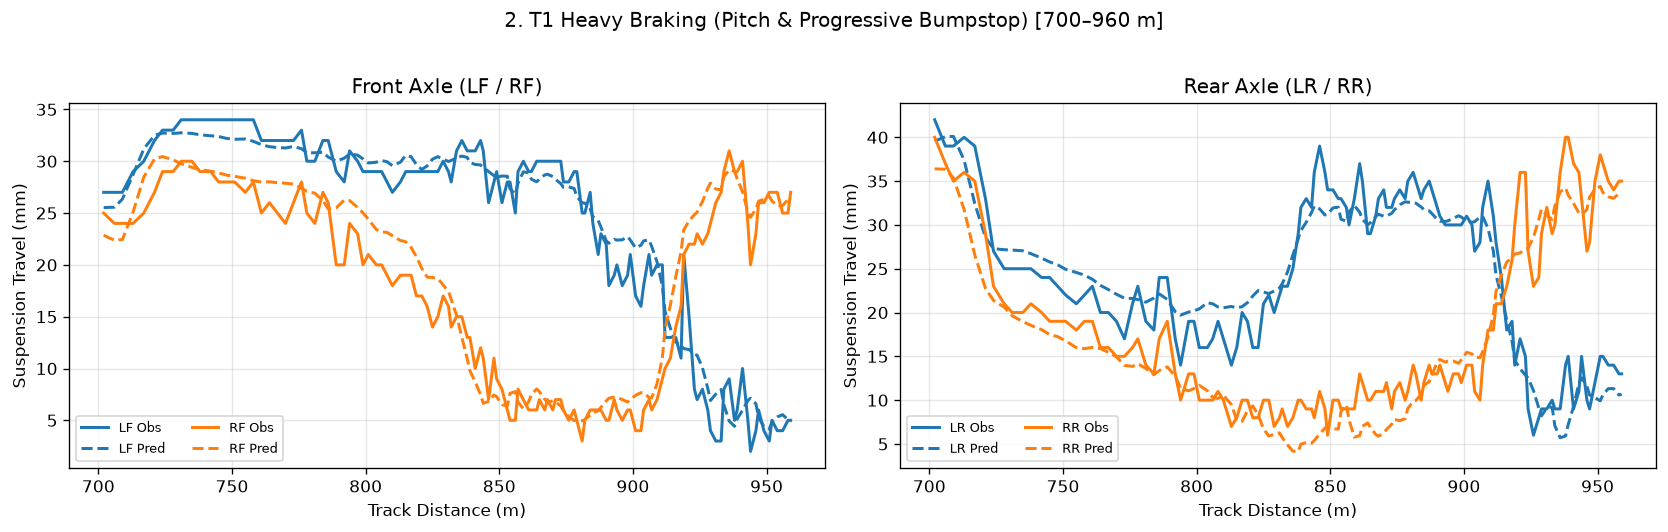

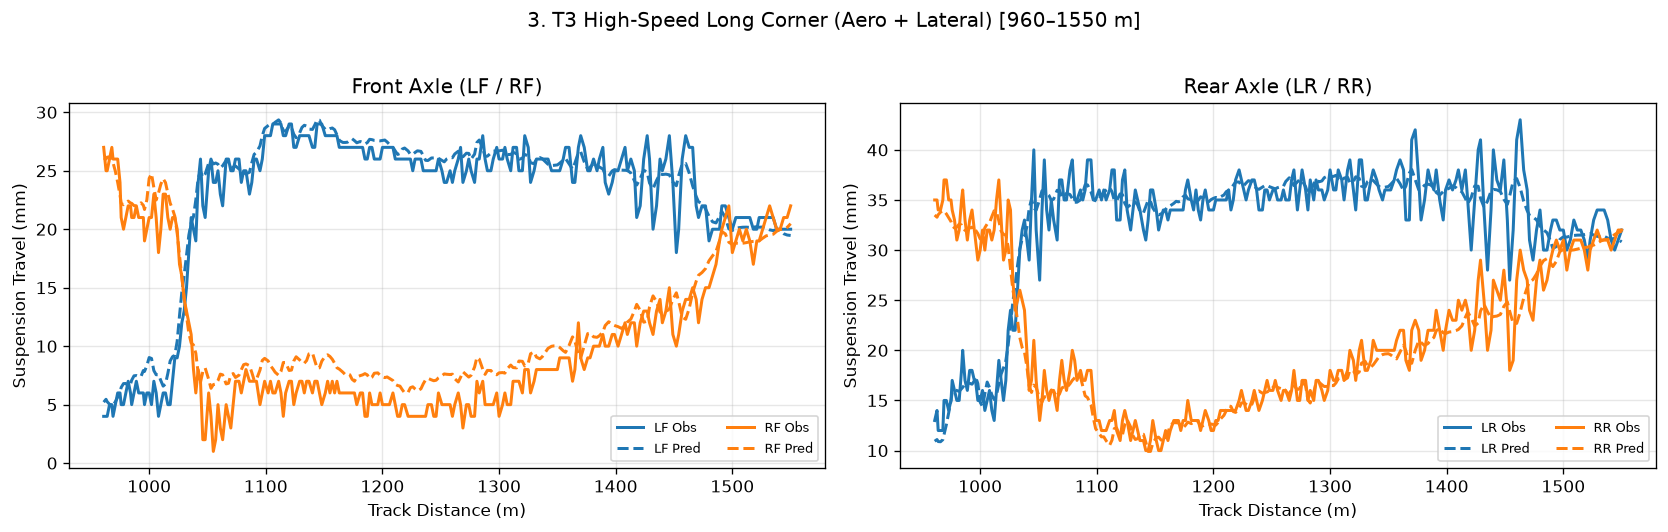

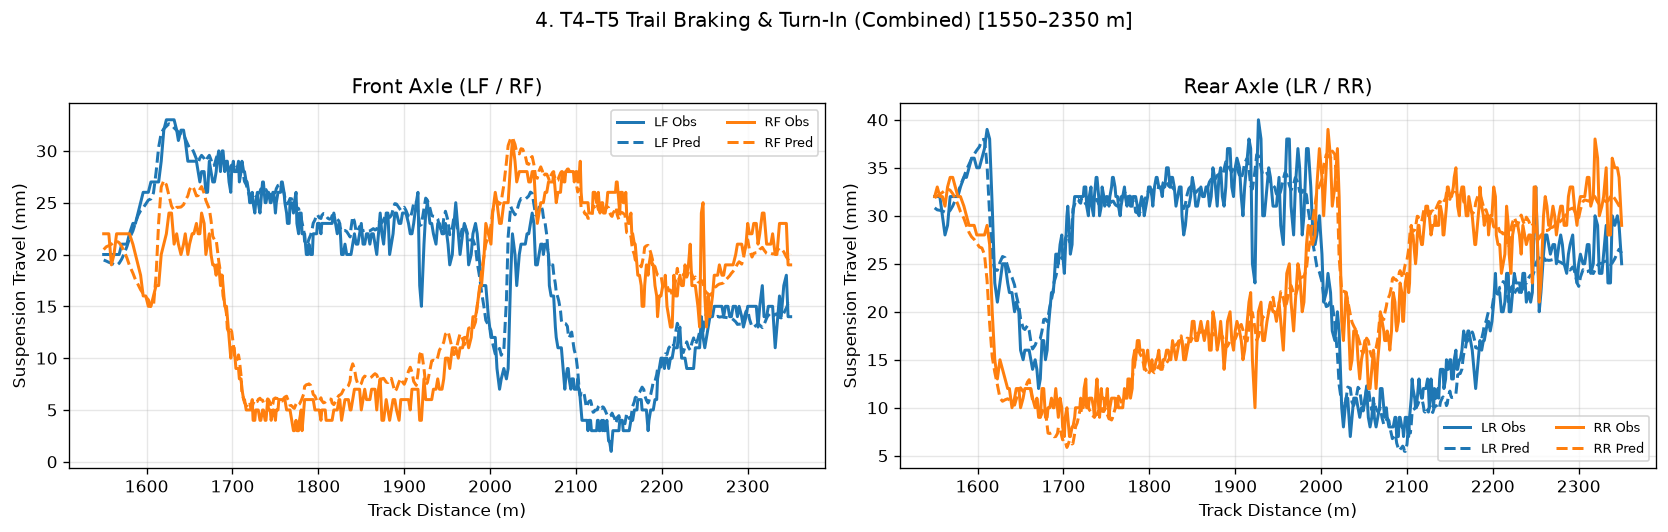

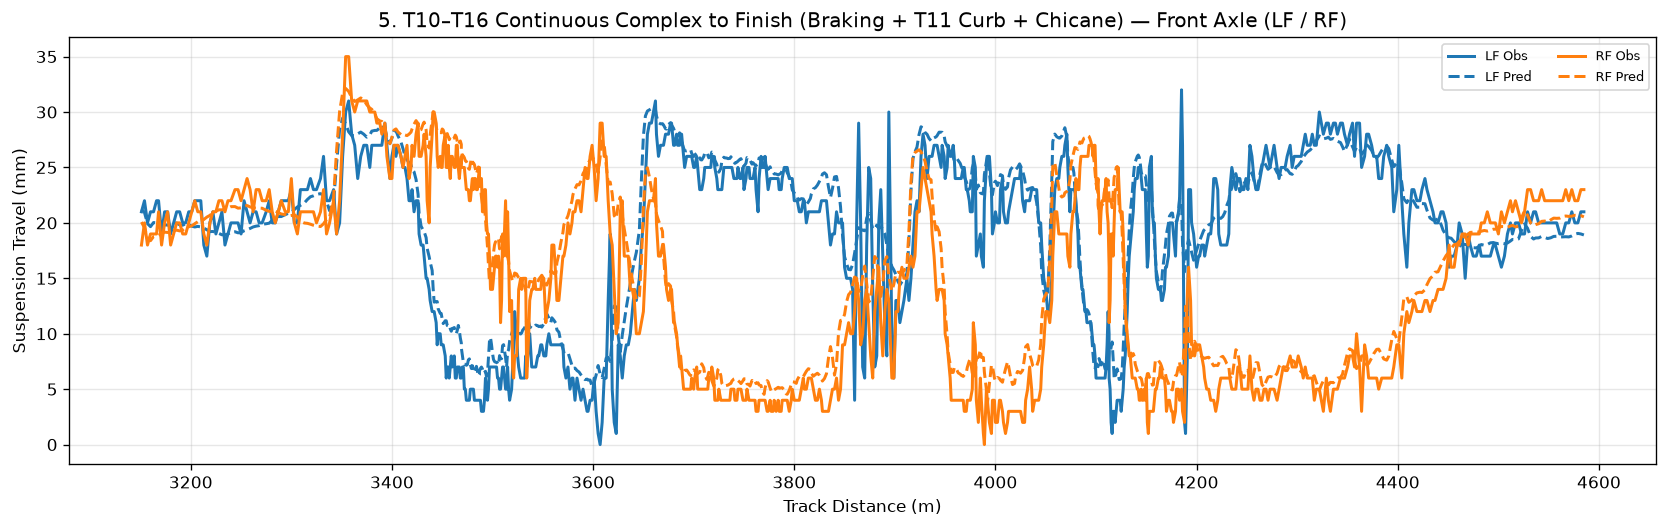

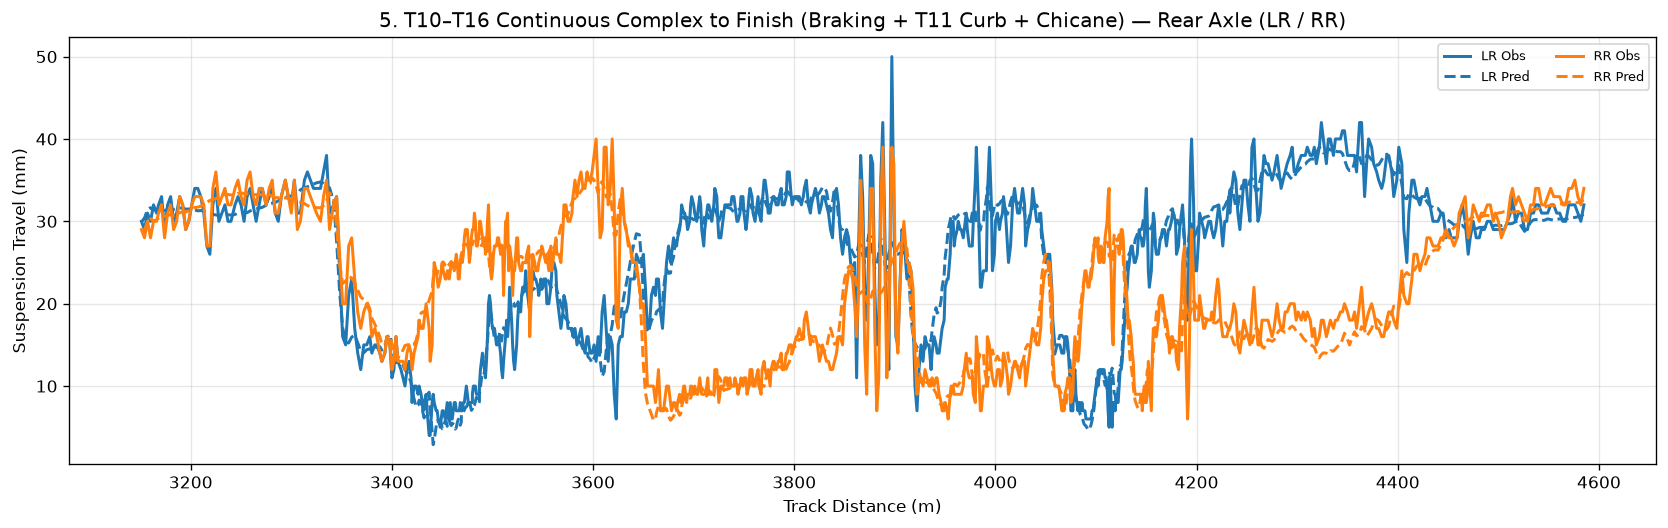

Saved report and figures to /mnt/c/LocalD/ACC_Modeling/outputs/stage3_barcelona_gt3_verification


In [4]:
scen_rows = []
for label, scenarios in [('Training', scen_tr), ('Verification', scen_val)]:
    for s in scenarios:
        scen_rows.append({
            'Dataset': label,
            'Scenario': s.label,
            'Samples': s.n_samples,
            'Mean Corner RMSE (mm)': s.mean_corner_rmse_mm,
            'LF (mm)': s.corner_rmse_mm['LF'],
            'RF (mm)': s.corner_rmse_mm['RF'],
            'LR (mm)': s.corner_rmse_mm['LR'],
            'RR (mm)': s.corner_rmse_mm['RR'],
            'Max BS Obs (N)': s.max_bs_force_obs_n,
            'Max BS Pred (N)': s.max_bs_force_pred_n,
        })
display(pd.DataFrame(scen_rows))

def plot_axle_pair(ax, d, obs_a, pred_a, obs_b, pred_b, label_a, label_b, title):
    ax.plot(d, obs_a, color='tab:blue', lw=1.8, label=f'{label_a} Obs')
    ax.plot(d, pred_a, color='tab:blue', ls='--', lw=1.8, label=f'{label_a} Pred')
    ax.plot(d, obs_b, color='tab:orange', lw=1.8, label=f'{label_b} Obs')
    ax.plot(d, pred_b, color='tab:orange', ls='--', lw=1.8, label=f'{label_b} Pred')
    ax.set_title(title)
    ax.set_xlabel('Track Distance (m)')
    ax.set_ylabel('Suspension Travel (mm)')
    ax.legend(ncol=2, fontsize=8)

for key, label, d0, d1 in SCENARIO_WINDOWS_M[:4]:
    mask = (dist >= d0) & (dist <= d1)
    d = dist[mask]
    fig, (ax_f, ax_r) = plt.subplots(1, 2, figsize=(14, 4.3))
    plot_axle_pair(
        ax_f, d,
        state_tr.z_obs_mm['LF'][mask], state_tr.z_pred_mm['LF'][mask],
        state_tr.z_obs_mm['RF'][mask], state_tr.z_pred_mm['RF'][mask],
        'LF', 'RF', 'Front Axle (LF / RF)',
    )
    plot_axle_pair(
        ax_r, d,
        state_tr.z_obs_mm['LR'][mask], state_tr.z_pred_mm['LR'][mask],
        state_tr.z_obs_mm['RR'][mask], state_tr.z_pred_mm['RR'][mask],
        'LR', 'RR', 'Rear Axle (LR / RR)',
    )
    fig.suptitle(f'{label} [{d0:.0f}–{d1:.0f} m]', y=1.02, fontsize=12)
    fig.tight_layout()
    show_and_save(fig, OUT_DIR / f'{key}.png')

_, label_s5, d0_s5, d1_s5 = SCENARIO_WINDOWS_M[4]
mask_s5 = (dist >= d0_s5) & (dist <= d1_s5)
d_s5 = dist[mask_s5]

# Segment 5 Front Axle (separate full-width figure)
fig_f, ax_f = plt.subplots(1, 1, figsize=(14, 4.5))
plot_axle_pair(
    ax_f, d_s5,
    state_tr.z_obs_mm['LF'][mask_s5], state_tr.z_pred_mm['LF'][mask_s5],
    state_tr.z_obs_mm['RF'][mask_s5], state_tr.z_pred_mm['RF'][mask_s5],
    'LF', 'RF', f'{label_s5} — Front Axle (LF / RF)',
)
fig_f.tight_layout()
show_and_save(fig_f, OUT_DIR / '5a_t10_t16_front.png')

# Segment 5 Rear Axle (separate full-width figure)
fig_r, ax_r = plt.subplots(1, 1, figsize=(14, 4.5))
plot_axle_pair(
    ax_r, d_s5,
    state_tr.z_obs_mm['LR'][mask_s5], state_tr.z_pred_mm['LR'][mask_s5],
    state_tr.z_obs_mm['RR'][mask_s5], state_tr.z_pred_mm['RR'][mask_s5],
    'LR', 'RR', f'{label_s5} — Rear Axle (LR / RR)',
)
fig_r.tight_layout()
show_and_save(fig_r, OUT_DIR / '5b_t10_t16_rear.png')

report = {
    'experiment_name': cfg.experiment_name,
    'aero_drag': {'training': aero_tr.to_dict(), 'verification': aero_val.to_dict()},
    'scenarios': {
        'training': [s.to_dict() for s in scen_tr],
        'verification': [s.to_dict() for s in scen_val],
    },
}
with open(OUT_DIR / 'report.json', 'w', encoding='utf-8') as f:
    json.dump(report, f, indent=2)
print(f'Saved report and figures to {OUT_DIR}')